# Clase 8 — Construcción de variables (RFM)

**Laboratorio de Modelo Analítico para la Toma de Decisiones**
ISTEA · 2026-2C · División A

---

La clase pasada la matriz de correlación del dataset estaba casi vacía: ninguna columna
cruda explicaba nada. Hoy construimos variables nuevas **a partir de esas mismas
columnas** y la señal aparece.

Ese es todo el contenido de la clase, y es el concepto más usado del oficio:

> **Ninguna fila de transacción sabe si el cliente se fue. Un cliente sí.**
> Cambiar la unidad de análisis es lo que hace aparecer la información.

| Parte | Qué es | Cuándo |
| --- | --- | --- |
| **A** | De 25.369 transacciones a 3.066 clientes | Lo hacemos juntos |
| **B** | La tabla de clientes de **tu** dataset | Segunda hora, en equipo |

> **La tabla que armamos hoy es el insumo de las clases 11, 12 y 13**: segmentación,
> modelo de abandono y umbral económico. Si queda bien construida, todo lo que viene
> es casi mecánico.

**El parcial 1 es el viernes que viene, 09/10.** Al final del notebook hay un repaso.

---
# PARTE A · ElecCommSphere

## A0 · El punto de partida de siempre

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
AZUL, GRIS, ROJO, VERDE = "#0A2FF1", "#6E7280", "#B4341F", "#1E7A46"

tx  = pd.read_csv("eleccommsphere_transacciones.csv", parse_dates=["fecha"])
cli = pd.read_csv("eleccommsphere_clientes.csv", parse_dates=["fecha_alta"])

t = tx.drop_duplicates()
t = t[t["id_cliente"].isin(cli["id_cliente"])]
t["categoria"] = (t["categoria"].str.strip().str.lower()
                    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8"))
t = t[t["monto"].notna() & (t["monto"] > 0)]
t = t[t["monto"] <= t["monto"].quantile(0.999)]

print(f"Transacciones limpias: {len(t):,}")
print(f"Clientes distintos   : {t['id_cliente'].nunique():,}")

Transacciones limpias: 25,369
Clientes distintos   : 3,283


## A1 · Las dos ventanas

Para hablar de abandono hacen falta **dos períodos**: uno para observar el
comportamiento y otro, posterior, para ver qué pasó.

Si se usa el mismo período para las dos cosas, se está usando información del futuro
para predecir el pasado. Eso se llama **fuga de información** y es el error más caro
de todo el proceso, porque no da ningún mensaje de error y los resultados salen
*mejores*.

In [2]:
CORTE = pd.Timestamp("2026-03-31")

obs  = t[t["fecha"] <= CORTE]     # observamos
post = t[t["fecha"] >  CORTE]     # medimos el resultado

print(f"Observación : {obs['fecha'].min().date()} → {obs['fecha'].max().date()}   {len(obs):>7,} tx")
print(f"Resultado   : {post['fecha'].min().date()} → {post['fecha'].max().date()}   {len(post):>7,} tx")
print(f"\nQuince meses para construir las variables, tres para etiquetar.")

Observación : 2025-01-06 → 2026-03-31    20,188 tx
Resultado   : 2026-04-01 → 2026-06-30     5,181 tx

Quince meses para construir las variables, tres para etiquetar.


> **Cómo se elige el corte.** La ventana de resultado tiene que durar lo que dura el
> ciclo del negocio. Muy corta y casi nadie figura como perdido; muy larga y queda poca
> historia para construir variables. Es una decisión arbitraria y está bien que lo sea:
> lo que no está bien es no declararla.

## A2 · RFM: las tres de siempre

**R**ecencia, **F**recuencia, **M**onto. Tiene cincuenta años, es anterior a cualquier
modelo de machine learning y sigue siendo la base de casi todo análisis de clientes
que funciona.

In [3]:
g = obs.groupby("id_cliente")

X = pd.DataFrame({
    "recencia":   (CORTE - g["fecha"].max()).dt.days,   # días desde la última compra
    "frecuencia": g.size(),                              # cuántas veces compró
    "monto":      g["monto"].sum(),                      # cuánto gastó en total
})

# La etiqueta sale de la OTRA ventana. Nunca de obs.
X["churn"] = ~X.index.isin(post["id_cliente"])

print(f"Clientes en la ventana : {len(X):,}")
print(f"Tasa de abandono       : {X['churn'].mean():.1%}")
X.head()

Clientes en la ventana : 3,066
Tasa de abandono       : 45.6%


,recencia,frecuencia,monto,churn
id_cliente,,,,
3,42,4,1043452.13,False
6,168,1,308506.33,False
7,191,2,805543.74,True
9,133,2,220917.15,True
10,124,5,758844.09,False


**Fijate en el `~X.index.isin(post...)`.** La etiqueta pregunta una sola cosa: ¿este
cliente aparece en la ventana de resultado? Si no aparece, se fue. Ninguna de las tres
variables de la izquierda mira `post`, y ninguna línea de `post` entra en el cálculo
de las variables. Esa separación es lo que evita la fuga.

## A3 · ¿Separan? La recencia primero

In [4]:
X["qR"] = pd.qcut(X["recencia"].rank(method="first"), 5,
                  labels=["R1 (reciente)", "R2", "R3", "R4", "R5 (lejano)"])

resR = X.groupby("qR", observed=True).agg(
    clientes = ("churn", "size"),
    dias     = ("recencia", "mean"),
    churn    = ("churn", "mean"),
)
resR["churn"] = (resR["churn"] * 100).round(1)
resR.round(1)

,clientes,dias,churn
qR,,,
R1 (reciente),614,6.2,20.4
R2,613,24.8,26.9
R3,613,55.5,40.8
R4,613,105.8,59.9
R5 (lejano),613,223.4,80.1


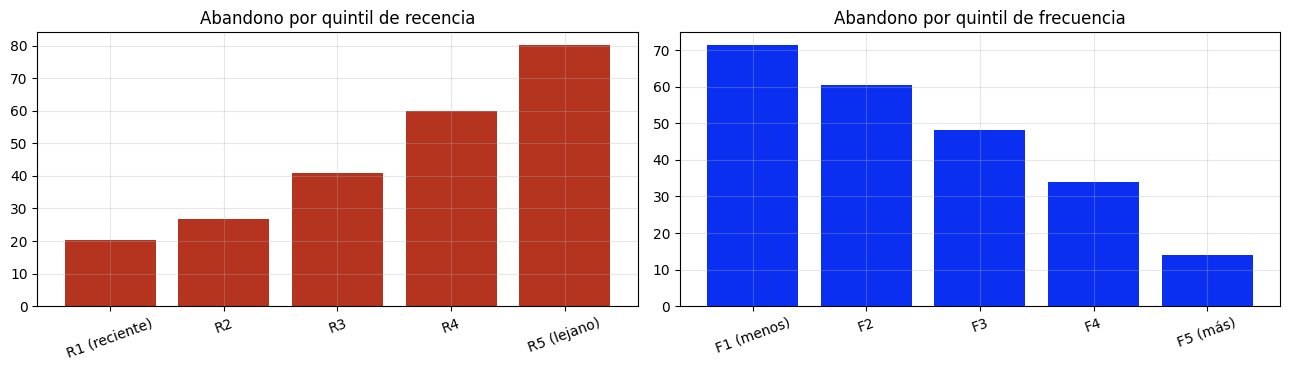

,clientes,compras,churn
qF,,,
F1 (menos),614,1.2,71.3
F2,613,2.5,60.5
F3,613,4.5,48.3
F4,613,7.4,33.9
F5 (más),613,17.3,13.9


In [5]:
X["qF"] = pd.qcut(X["frecuencia"].rank(method="first"), 5,
                  labels=["F1 (menos)", "F2", "F3", "F4", "F5 (más)"])
resF = X.groupby("qF", observed=True).agg(
    clientes = ("churn", "size"),
    compras  = ("frecuencia", "mean"),
    churn    = ("churn", "mean"),
)
resF["churn"] = (resF["churn"] * 100).round(1)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(resR.index.astype(str), resR["churn"], color=ROJO)
ax[0].set_title("Abandono por quintil de recencia"); ax[0].set_ylim(0, None)
ax[0].tick_params(axis="x", rotation=20)

ax[1].bar(resF.index.astype(str), resF["churn"], color=AZUL)
ax[1].set_title("Abandono por quintil de frecuencia"); ax[1].set_ylim(0, None)
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
resF.round(1)

> **Las dos son monótonas, y en direcciones opuestas.** La recencia sube de 20,4 % a
> 80,1 %; la frecuencia baja de 71,3 % a 13,9 %.
>
> Comparalo con el gráfico de la clase pasada, donde la tasa de búsqueda fallida daba
> una U invertida. La diferencia no está en los datos: está en que estas variables se
> construyeron bien y aquella arrastraba un problema de denominador.

**`.rank(method="first")` otra vez.** La frecuencia tiene muchísimos empates —un montón
de clientes con una sola compra— y sin el rank los cortes de los quintiles colapsan.

## A4 · El perfil: quién se va y quién se queda

In [6]:
perfil = X.groupby("churn")[["recencia", "frecuencia", "monto"]].mean().T
perfil.columns = ["Se queda", "Se va"]
perfil["Diferencia %"] = ((perfil["Se va"] / perfil["Se queda"] - 1) * 100).round(1)
perfil.round(2)

,Se queda,Se va,Diferencia %
recencia,50.61,121.91,140.9
frecuencia,8.88,3.85,-56.6
monto,1626139.39,701859.19,-56.8


El que se va tiene la última compra **141 % más lejos**, compra **57 % menos veces** y
gasta **57 % menos en total**.

Ahora agreguemos una cuarta variable y miremos qué pasa.

## A5 · Variables derivadas: cinco más del mismo groupby

In [7]:
X["ticket"]     = X["monto"] / X["frecuencia"]
X["antiguedad"] = (CORTE - g["fecha"].min()).dt.days
X["categorias"] = g["categoria"].nunique()
X["canales"]    = g["canal"].nunique()
X["tasa_dev"]   = g["devuelto"].mean()
X["intensidad"] = X["frecuencia"] / X["antiguedad"].clip(lower=1)

cols = ["recencia", "frecuencia", "monto", "ticket",
        "antiguedad", "categorias", "canales", "tasa_dev", "intensidad"]

perfil2 = X.groupby("churn")[cols].mean().T
perfil2.columns = ["Se queda", "Se va"]
perfil2["Diferencia %"] = ((perfil2["Se va"] / perfil2["Se queda"] - 1) * 100).round(1)
perfil2["Correlación"] = [np.corrcoef(X[c], X["churn"])[0, 1].round(3) for c in cols]
perfil2.round(2)

,Se queda,Se va,Diferencia %,Correlación
recencia,50.61,121.91,140.9,0.42
frecuencia,8.88,3.85,-56.6,-0.36
monto,1626139.39,701859.19,-56.8,-0.33
ticket,183505.60,179163.71,-2.4,-0.02
antiguedad,262.63,251.01,-4.4,-0.05
categorias,3.42,2.40,-30.0,-0.37
canales,2.74,2.01,-26.6,-0.35
tasa_dev,0.07,0.07,10.8,0.02
intensidad,0.04,0.02,-48.9,-0.20


> **Mirá la fila del ticket promedio.** $ 183.506 contra $ 179.164: una diferencia del
> 2 % y correlación prácticamente cero. **El ticket no distingue a nadie.**
>
> Es el mismo hallazgo de la clase de EDA, ahora a nivel cliente: el que se va no gasta
> menos por compra, compra menos veces. El problema no es el precio.

Y eso importa para lo que viene: **una variable sin señal no es neutra, agrega ruido**.
Saber cuál no sirve es tan útil como saber cuál sirve.

## A6 · Lo que acaba de pasar

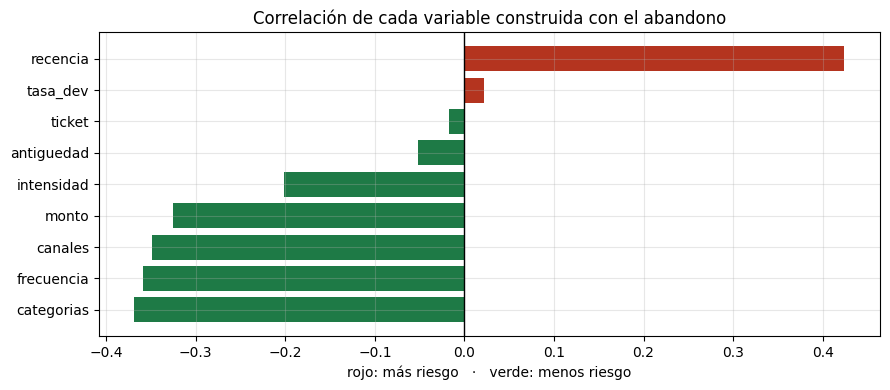

Transacciones de entrada : 25,369
Filas de la tabla final  : 3,066
Columnas construidas     : 9


In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
corr = pd.Series({c: np.corrcoef(X[c], X["churn"])[0, 1] for c in cols}).sort_values()
colores = [ROJO if v > 0 else VERDE for v in corr]
ax.barh(corr.index, corr.values, color=colores)
ax.axvline(0, color="k", lw=1)
ax.set_title("Correlación de cada variable construida con el abandono")
ax.set_xlabel("rojo: más riesgo   ·   verde: menos riesgo")
plt.tight_layout(); plt.show()

print(f"Transacciones de entrada : {len(t):,}")
print(f"Filas de la tabla final  : {len(X):,}")
print(f"Columnas construidas     : {len(cols)}")

25.369 filas de transacciones se volvieron 3.066 filas de clientes. Se perdieron 25.000
filas y se ganó la posibilidad de predecir.

**La tabla que importa casi nunca es la que viene en el archivo.**

## A7 · Tres trampas al construir variables

In [9]:
# 1. El cliente de una sola compra
print("Clientes con una sola compra:", (X["frecuencia"] == 1).sum(),
      f"({(X['frecuencia']==1).mean():.1%})")
print("   churn de ese grupo:", f"{X.loc[X['frecuencia']==1, 'churn'].mean():.1%}")

# 2. La tasa sobre pocos eventos
pocos = X[X["frecuencia"] <= 2]
print(f"\nClientes con 2 compras o menos: {len(pocos):,}")
print("   su tasa de devolución solo puede valer 0, 0,5 o 1 — no es comparable")

# 3. La variable que mira el futuro
mal = (t["fecha"].max() - g["fecha"].max()).dt.days      # ← usa el máximo del ARCHIVO
bien = (CORTE - g["fecha"].max()).dt.days                 # ← usa el CORTE
print(f"\nRecencia mal calculada (contra el fin del archivo): media {mal.mean():.0f} días")
print(f"Recencia bien calculada (contra el corte)         : media {bien.mean():.0f} días")
print("La primera usa información posterior al corte. Corre igual y está mal.")

Clientes con una sola compra: 519 (16.9%)
   churn de ese grupo: 72.4%

Clientes con 2 compras o menos: 904
   su tasa de devolución solo puede valer 0, 0,5 o 1 — no es comparable

Recencia mal calculada (contra el fin del archivo): media 174 días
Recencia bien calculada (contra el corte)         : media 83 días
La primera usa información posterior al corte. Corre igual y está mal.


**La tercera es la más difícil de ver** porque el código no falla. La regla práctica:
toda fecha que aparezca en una fórmula tiene que ser **el corte**, nunca la fecha de
hoy ni el máximo del archivo completo.

## A8 · Escalar, y por qué

Antes de medir distancias entre clientes —que es lo que hace K-Means en la clase 11—
hay que poner todas las variables en la misma escala.

In [10]:
from sklearn.preprocessing import StandardScaler

tres = ["recencia", "frecuencia", "monto"]
print("Antes de escalar:")
print(X[tres].describe().loc[["min", "max", "std"]].round(0).to_string())

esc = pd.DataFrame(StandardScaler().fit_transform(X[tres]), columns=tres, index=X.index)
print("\nDespués de escalar:")
print(esc.describe().loc[["min", "max", "std"]].round(2).to_string())

Antes de escalar:
     recencia  frecuencia       monto
min       0.0         1.0      9461.0
max     434.0        64.0  17745860.0
std      84.0         7.0   1413125.0

Después de escalar:
     recencia  frecuencia  monto
min     -0.99       -0.80  -0.85
max      4.19        8.24  11.71
std      1.00        1.00   1.00


El monto llega a diecisiete millones y la frecuencia a sesenta y cuatro. Para un
algoritmo que suma diferencias al cuadrado, **la frecuencia directamente no existe**:
sin escalar, K-Means agruparía casi exclusivamente por monto.

Los pesos no se eligen — los impone la unidad de medida, salvo que uno intervenga.

> **Cuándo hace falta:** siempre que el método mida distancias (K-Means, vecinos más
> cercanos) o compare coeficientes entre variables. No hace falta para árboles ni
> bosques aleatorios.

## A9 · Guardar la tabla

In [11]:
X.drop(columns=["qR", "qF"]).to_csv("ecs_clientes.csv")
print("Guardada como ecs_clientes.csv")
print(X.drop(columns=['qR','qF']).shape, "— una fila por cliente")

Guardada como ecs_clientes.csv
(3066, 10) — una fila por cliente


---
# PARTE B · Tu dataset

## B0 · Los nombres de siempre, más uno

Además de los tres de siempre hace falta decidir **la fecha de corte**.

In [ ]:
import pandas as pd
import numpy as np

# ── Cargá tu dataset limpio ───────────────────────────────────────────────
# mi = pd.read_csv("mi_dataset_limpio.csv", parse_dates=["fecha"])

ID    = "id_cliente"
FECHA = "fecha"
VALOR = "monto"

mi = t.copy()          # mientras no cargues el tuyo, corre sobre ElecCommSphere
print("Trabajando sobre:", mi.shape)
print("Período:", mi[FECHA].min().date(), "→", mi[FECHA].max().date())

## B1 · Elegir el corte

Mirá tu serie mensual y decidí dónde partir. La ventana de resultado tiene que ser lo
suficientemente larga como para que **no volver signifique algo** en tu negocio.

In [ ]:
serie = mi.set_index(FECHA).resample("ME").size()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(serie.index, serie, marker="o", ms=3, color="#0A2FF1")
ax.set_ylim(0, None); ax.set_title("Volumen mensual — ¿dónde conviene cortar?")
plt.tight_layout(); plt.show()

print("Últimos seis meses del archivo:")
print(serie.tail(6).to_string())

In [ ]:
# ── Tu decisión ───────────────────────────────────────────────────────────
MI_CORTE = pd.Timestamp("2026-03-31")      # ← cambiá esta fecha

obs_b  = mi[mi[FECHA] <= MI_CORTE]
post_b = mi[mi[FECHA] >  MI_CORTE]

print(f"Observación : {len(obs_b):>8,} filas   ({obs_b[FECHA].min().date()} → {obs_b[FECHA].max().date()})")
print(f"Resultado   : {len(post_b):>8,} filas   ({post_b[FECHA].min().date()} → {post_b[FECHA].max().date()})")
print(f"\nIdentificadores en la ventana de observación: {obs_b[ID].nunique():,}")

**Escribí acá por qué elegiste esa fecha.** Va en el trabajo final.

_(tu justificación)_

## B2 · Construir RFM — o RFE

In [ ]:
gb = obs_b.groupby(ID)

B = pd.DataFrame({
    "recencia":   (MI_CORTE - gb[FECHA].max()).dt.days,
    "frecuencia": gb.size(),
    "valor":      gb[VALOR].sum(),      # monto si hay plata, suma de puntaje si no
})
B["churn"] = ~B.index.isin(post_b[ID])

print(f"Identificadores : {len(B):,}")
print(f"Tasa de abandono: {B['churn'].mean():.1%}")
B.describe().round(2)

> **Si tu dataset mide en puntaje** (MovieLens y las cinco categorías de Amazon), la M
> de monto pasa a ser **E de engagement**: la suma del puntaje, el promedio, o la
> cantidad de productos distintos reseñados. Recencia y frecuencia funcionan igual.
> Lo que cambia es la pregunta de negocio, no la dificultad — y va declarado.

> **Si tu etiqueta no puede ser abandono** —porque el filtro 5-core se llevó justamente
> a los que abandonan— podés etiquetar otra cosa: que el producto cruce un umbral de
> calificación, que el vendedor deje de publicar, que el hogar deje de canjear cupones.
> La mecánica es idéntica, solo cambia qué pregunta `post_b`.

## B3 · ¿Separan?

In [ ]:
B["qR"] = pd.qcut(B["recencia"].rank(method="first"), 5,
                  labels=["R1", "R2", "R3", "R4", "R5"])
B["qF"] = pd.qcut(B["frecuencia"].rank(method="first"), 5,
                  labels=["F1", "F2", "F3", "F4", "F5"])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, q, tit, col in [(ax[0], "qR", "Abandono por quintil de recencia", "#B4341F"),
                       (ax[1], "qF", "Abandono por quintil de frecuencia", "#0A2FF1")]:
    s = B.groupby(q, observed=True)["churn"].mean() * 100
    a.bar(s.index.astype(str), s.values, color=col)
    a.set_ylim(0, None); a.set_title(tit); a.set_ylabel("% de abandono")
plt.tight_layout(); plt.show()

**Las preguntas:** ¿suben y bajan de forma limpia, o hay saltos raros? Si alguna da una
U invertida como la búsqueda fallida de la clase pasada, revisá el denominador antes de
seguir.

## B4 · Tres variables derivadas

Elegí **tres** y justificá por qué esas. Cada una es una hipótesis sobre por qué tu
cliente se va.

In [ ]:
B["ticket"]     = B["valor"] / B["frecuencia"]
B["antiguedad"] = (MI_CORTE - gb[FECHA].min()).dt.days
B["intensidad"] = B["frecuencia"] / B["antiguedad"].clip(lower=1)

# ── Agregá acá las tuyas, con las columnas de tu archivo ──────────────────
# B["categorias"] = gb["categoria"].nunique()
# B["tasa_fric"]  = gb["devuelto"].mean()

mis_cols = ["recencia", "frecuencia", "valor", "ticket", "antiguedad", "intensidad"]

perfil_b = B.groupby("churn")[mis_cols].mean().T
perfil_b.columns = ["Se queda", "Se va"]
perfil_b["Diferencia %"] = ((perfil_b["Se va"] / perfil_b["Se queda"] - 1) * 100).round(1)
perfil_b["Correlación"]  = [np.corrcoef(B[c], B["churn"])[0, 1].round(3) for c in mis_cols]
perfil_b.round(2)

**La pregunta del taller:** ¿cuál separa más? ¿Alguna no separa nada?

Una variable con correlación cercana a cero no es neutra: agrega ruido al modelo.
Anotá cuáles descartarías y por qué — eso va en el trabajo final.

## B5 · Guardar la tabla

In [ ]:
B.drop(columns=["qR", "qF"]).to_csv("mi_tabla_clientes.csv")
print("Guardada:", B.drop(columns=['qR','qF']).shape, "— una fila por identificador")
print("\nEste archivo es el insumo de las clases 11, 12 y 13. Guardalo bien.")

---
## Repaso para el parcial · viernes 09/10

Individual, teórico y por formulario. **No hay que programar**: hay que explicar
criterios. Entra de la clase 2 a la de hoy.

### Las cinco respuestas que conviene tener listas

1. **¿Qué es la granularidad?** Qué representa una fila, verificado con una cuenta y no
   supuesto. De ahí depende todo lo demás.
2. **¿Cuándo borrar un nulo?** Solo después de mirar si falta al azar. Si la falta tiene
   patrón, borrar no limpia: cambia la composición de la muestra.
3. **¿Media o mediana?** Las dos, y la diferencia entre ambas es el hallazgo. Si
   difieren mucho hay cola larga o hay poblaciones mezcladas.
4. **¿Por qué el eje en cero?** Porque sin eso una diferencia del 3 % parece una
   montaña. Es la manipulación más común y casi nunca es intencional.
5. **¿Qué es la fuga de información?** Usar para predecir algo que solo se sabe después
   del hecho. Se detecta porque el resultado da sospechosamente bien.

Si pueden contestar estas cinco con sus propias palabras **y con un ejemplo de su
dataset**, el parcial está aprobado.

### Lo que no entra

La sintaxis de pandas de memoria. Nadie va a tener que escribir un `groupby` en el
formulario.

## Si se traban

Por mail durante la semana, con las cuatro cosas de siempre: qué intentaron, qué
esperaban, qué pasó, y el mensaje de error completo copiado y pegado. Si algo del
repaso no cierra, es mejor preguntarlo antes que el viernes.